# Comparación de métodos de segmentación (umbralización, método de Otsu y Machine Learning mediante Gaussian Naive Bayes) en imágenes RGB y su efecto en la estimación del área y el perímetro.

1. Conectar con Google Drive.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install -q plantcv

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
# ---------- Librerías estándar ----------
import os
import random

# ---------- Numéricas y datos ----------
import numpy as np
import pandas as pd

# ---------- Gráficos ----------
import matplotlib.pyplot as plt
import plotly.io
import plotly.express as px
from plotly.subplots import make_subplots

# ---------- scikit-image ----------
from skimage.io import imread
from skimage.filters import threshold_otsu
from skimage.measure import label, regionprops
from skimage.morphology import (remove_small_objects, remove_small_holes,
                                binary_opening, binary_closing, disk)

# ---------- scikit-learn ----------
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# ---------- PlantCV ----------
from plantcv import plantcv as pcv

2. Cargar y visualizar.

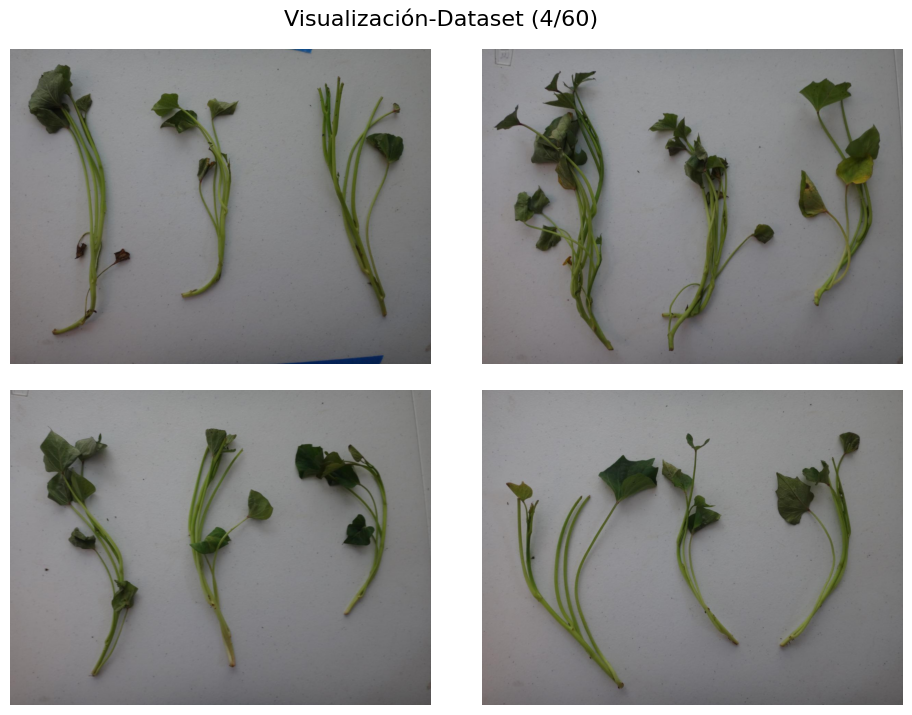

In [4]:
# Semilla para reproducibilidad
random.seed(42)
np.random.seed(42)

# Cargar las imágenes (ordenadas y solo archivos de imagen)
ruta = '/content/drive/MyDrive/Proyecto_Final/images'
archivos = sorted([f for f in os.listdir(ruta)
                   if f.lower().endswith(('.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp'))])

# Escala opcional (cm por píxel). Si es None, los resultados quedan en píxeles
escala = None

imagenes = []
for archivo in archivos:
    imagen = imread(ruta + '/' + archivo)
    imagenes.append(imagen)
    if len(imagenes) == 4:
        break

# Visualizar las imágenes
plt.figure(figsize=(12,8))
plt.suptitle('Visualización-Dataset (4/60)', fontsize=16)

for i in range(4):
    plt.subplot(2,2,i+1)
    plt.imshow(imagenes[i])
    plt.axis('off')

plt.subplots_adjust(top=0.93, hspace=0.08, wspace=0.03)
plt.show()

Segmentación: Umbralización RGB.

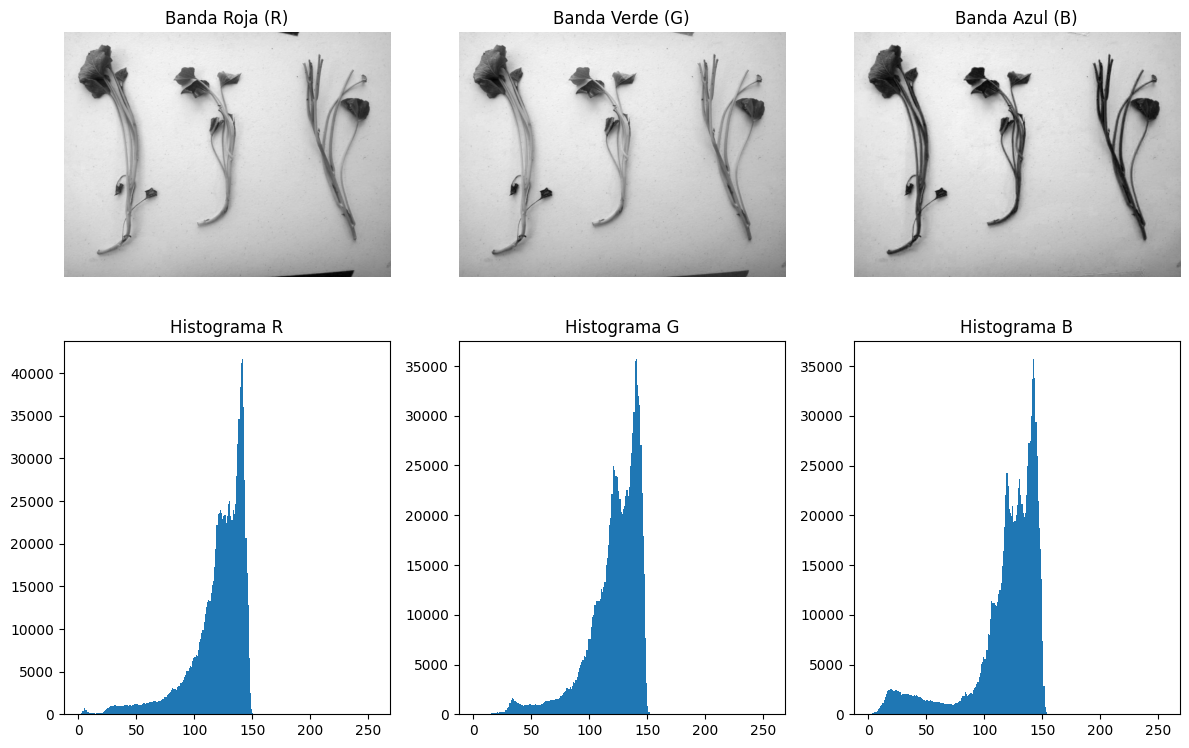

In [5]:
imagen = imread(ruta + '/' + archivos[0])

# Separar las bandas RGB
R = imagen[:,:,0]
G = imagen[:,:,1]
B = imagen[:,:,2]

# Visualizar las bandas RGB
plt.figure(figsize=(12,8))

plt.subplot(2,3,1)
plt.imshow(R, cmap='gray')
plt.title('Banda Roja (R)')
plt.axis('off')

plt.subplot(2,3,2)
plt.imshow(G, cmap='gray')
plt.title('Banda Verde (G)')
plt.axis('off')

plt.subplot(2,3,3)
plt.imshow(B, cmap='gray')
plt.title('Banda Azul (B)')
plt.axis('off')

# Visualizar los histogramas
plt.subplot(2,3,4)
plt.hist(R.ravel(), bins=256, range=(0,256))
plt.title('Histograma R')

plt.subplot(2,3,5)
plt.hist(G.ravel(), bins=256, range=(0,256))
plt.title('Histograma G')

plt.subplot(2,3,6)
plt.hist(B.ravel(), bins=256, range=(0,256))
plt.title('Histograma B')

plt.tight_layout()
plt.show()

Justificación del umbral: histograma de la banda azul (región recortada) de varias imágenes, con el umbral 85 y el de Otsu.

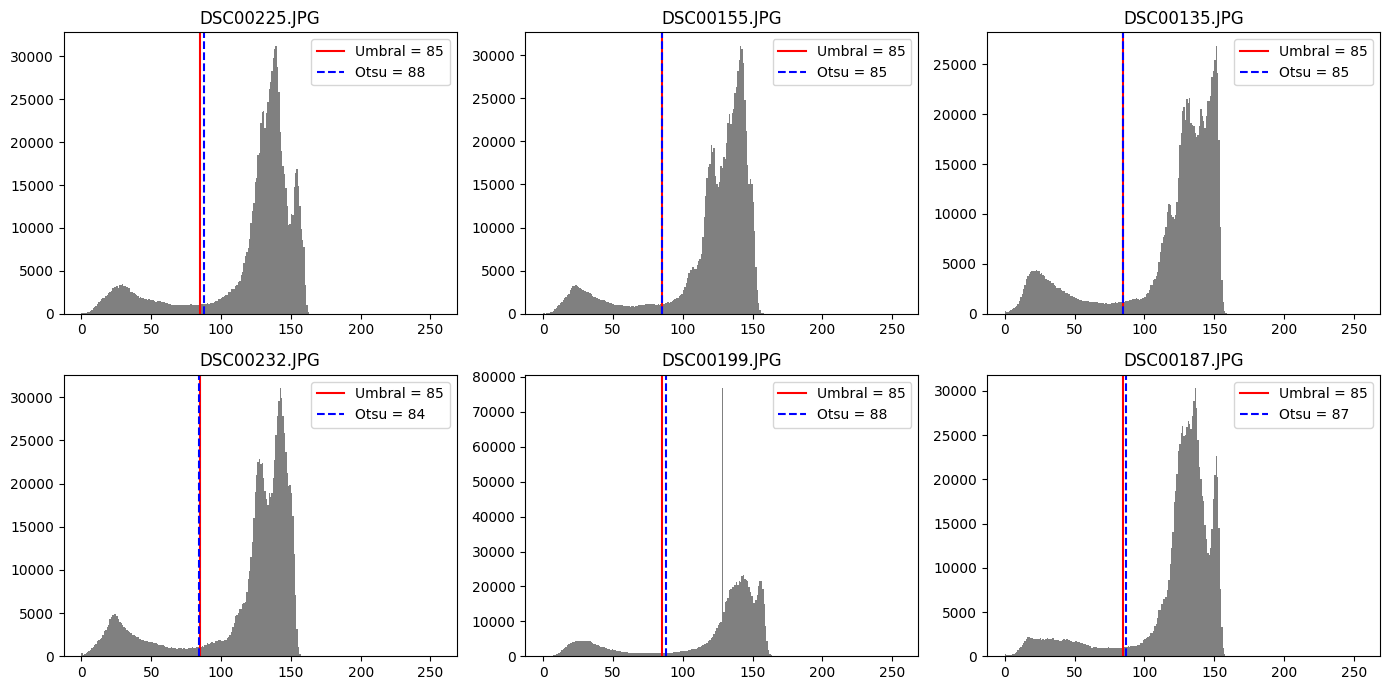

In [6]:
muestra = random.sample(archivos, 6)

plt.figure(figsize=(14,7))
for i, archivo in enumerate(muestra):
    imagen = imread(ruta + '/' + archivo)
    B = imagen[20:850, 20:1180, 2]

    plt.subplot(2,3,i+1)
    plt.hist(B.ravel(), bins=256, range=(0,256), color='gray')
    plt.axvline(85, color='r', label='Umbral = 85')
    plt.axvline(threshold_otsu(B), color='b', linestyle='--', label='Otsu = ' + str(threshold_otsu(B)))
    plt.title(archivo)
    plt.legend()

plt.tight_layout()
plt.show()

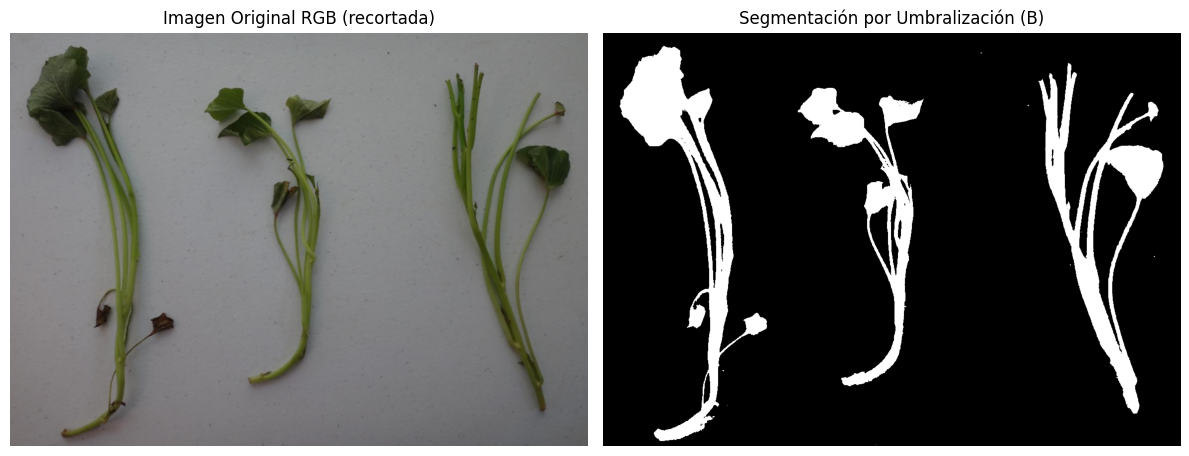

(830, 1160)


In [7]:
imagen = imread(ruta + '/' + archivos[0])

# Recortar primero la imagen
imagen_recortada = imagen[20:850, 20:1180]

# Extraer la banda azul
B = imagen_recortada[:,:,2]

# Segmentar la imagen
umbral = 85
segmentacion = B < umbral

# Visualizar la segmentación
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(imagen_recortada)
plt.title('Imagen Original RGB (recortada)')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(segmentacion, cmap='gray')
plt.title('Segmentación por Umbralización (B)')
plt.axis('off')

plt.tight_layout()
plt.show()
print(segmentacion.shape)

In [8]:
# Usar gráfico interactivo plotly para hacer zoom en zonas con problemas
mascara_recortada = segmentacion

fig = px.imshow(mascara_recortada, color_continuous_scale="gray")
fig.update_layout(title="Máscara Segmentada Recortada")
plotly.io.show(fig)

In [9]:
# Postprocesamiento (igual para los tres métodos):
# apertura y cierre, eliminar objetos pequeños y rellenar huecos pequeños
def postprocesar(mascara):
    mascara = mascara.astype(bool)
    mascara = binary_opening(mascara, disk(1))
    mascara = binary_closing(mascara, disk(1))
    try:
        # scikit-image nuevo
        mascara = remove_small_objects(mascara, max_size=99)
        mascara = remove_small_holes(mascara, max_size=99)
    except TypeError:
        # scikit-image anterior
        mascara = remove_small_objects(mascara, min_size=100)
        mascara = remove_small_holes(mascara, area_threshold=100)
    return mascara

In [12]:
# Visualizar imagen original y máscara posprocesada
from plotly.subplots import make_subplots

fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=('Imagen Original RGB', 'Máscara Posprocesada')
)

fig.add_trace(
    px.imshow(imagen_recortada).data[0],
    row=1, col=1
)

fig.add_trace(
    px.imshow(mascara_limpia, binary_string=True).data[0],
    row=1, col=2
)

fig.update_layout(
    title='Comparación de Segmentación',
    width=1100,
    height=550
)

plotly.io.show(fig)

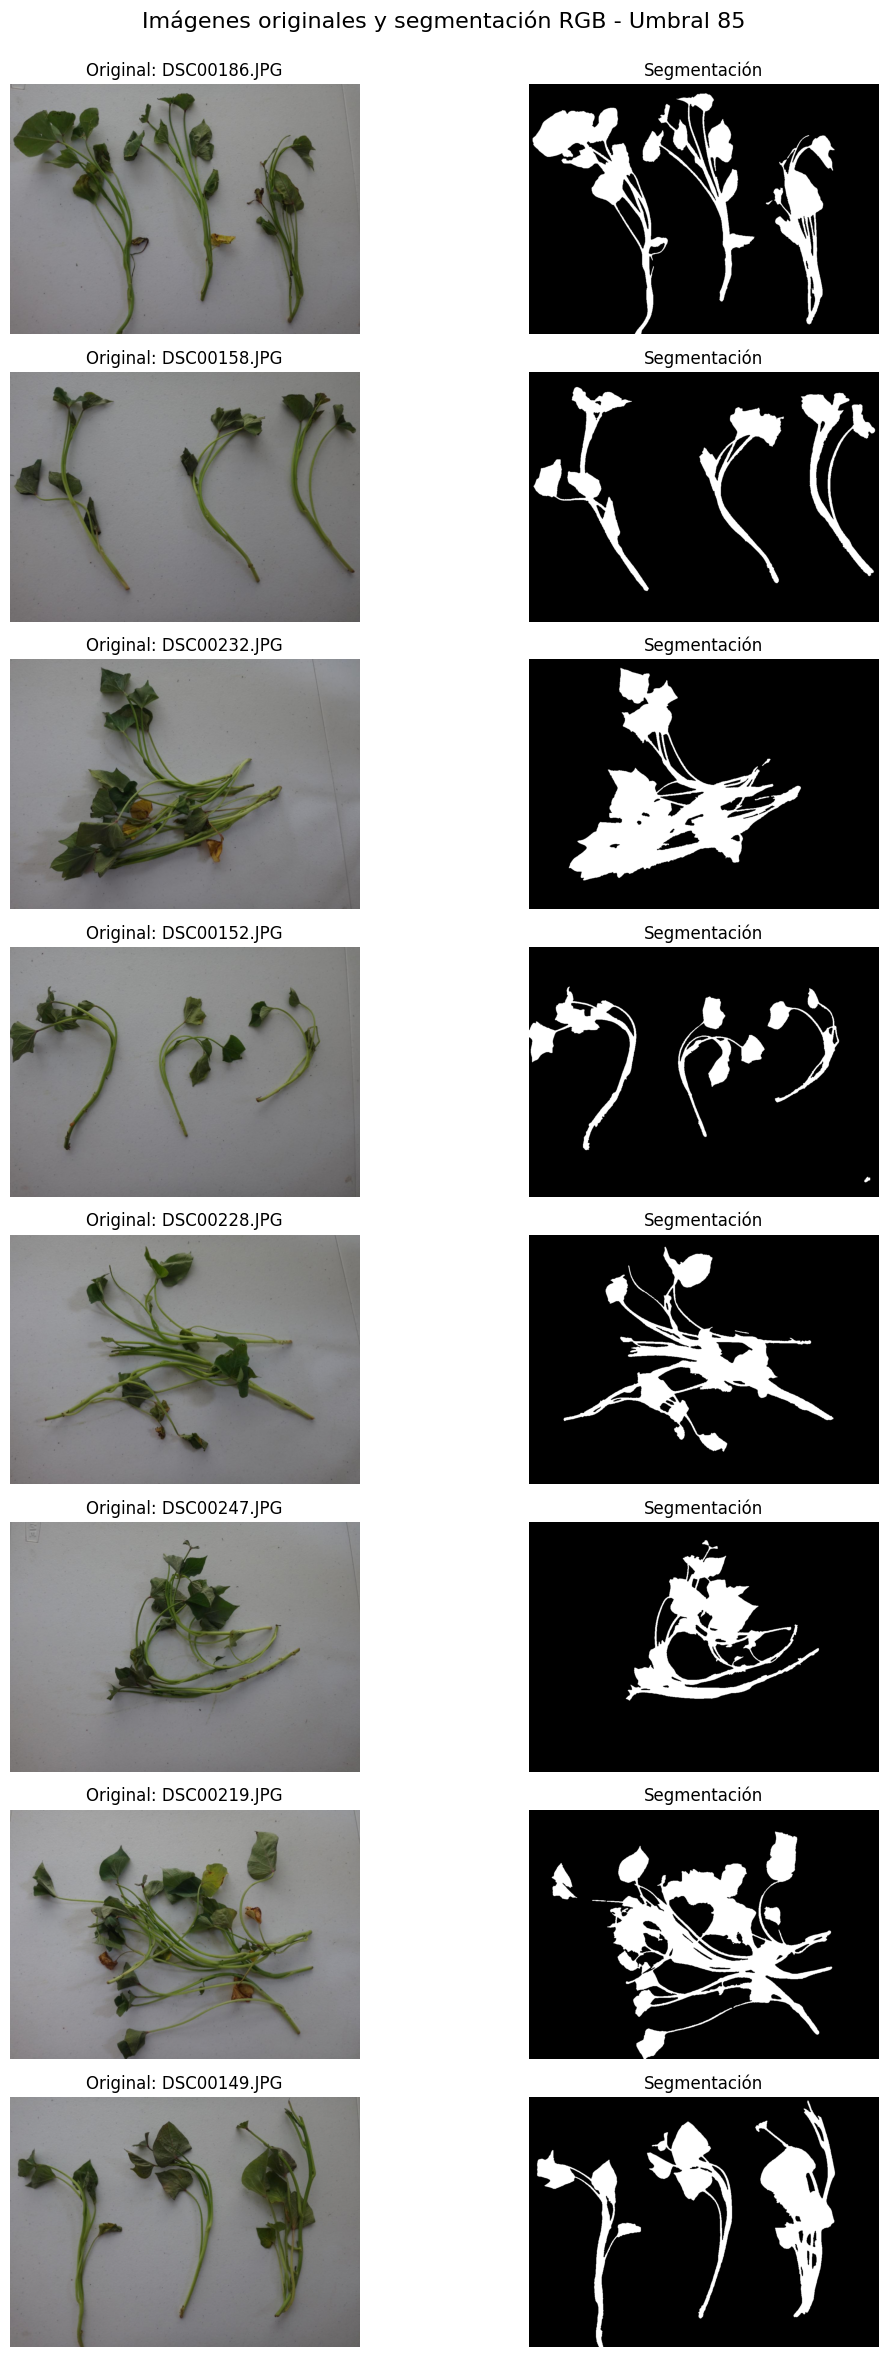

In [11]:
# Seleccionar 8 imágenes aleatorias
muestra = random.sample(archivos, 8)

# Visualizar imágenes originales y máscaras segmentadas
plt.figure(figsize=(12,24))
plt.suptitle('Imágenes originales y segmentación RGB - Umbral 85', fontsize=16)

for i, archivo in enumerate(muestra):
    # Cargar imagen y recortar
    imagen = imread(ruta + '/' + archivo)
    imagen_recortada = imagen[20:850, 20:1180]

    # Umbralizar canal azul
    B = imagen_recortada[:,:,2]
    segmentacion = B < 85

    # Postprocesar
    mascara_limpia = postprocesar(segmentacion)

    # Mostrar imagen original
    plt.subplot(8,2,2*i+1)
    plt.imshow(imagen_recortada)
    plt.title('Original: ' + archivo)
    plt.axis('off')

    # Mostrar máscara segmentada
    plt.subplot(8,2,2*i+2)
    plt.imshow(mascara_limpia, cmap='gray')
    plt.title('Segmentación')
    plt.axis('off')

plt.tight_layout(rect=[0,0,1,0.98])
plt.show()

Segmentación: Método de Otsu.

Umbral de Otsu: 85


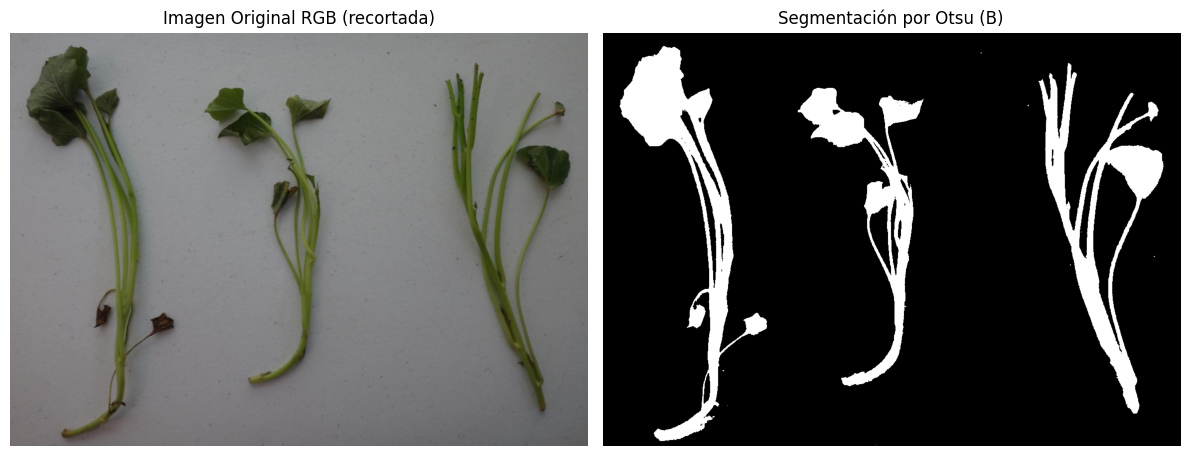

In [13]:
from skimage.filters import threshold_otsu

# Cargar la imagen 1 y recortar primero
imagen = imread(ruta + '/' + archivos[0])
imagen_recortada = imagen[20:850, 20:1180]

# Extraer la banda azul
B = imagen_recortada[:,:,2]

# Aplicar método de Otsu (solo sobre la región recortada)
umbral_otsu = threshold_otsu(B)
segmentacion_otsu = B < umbral_otsu

print('Umbral de Otsu:', umbral_otsu)

# Visualizar la segmentación
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(imagen_recortada)
plt.title('Imagen Original RGB (recortada)')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(segmentacion_otsu, cmap='gray')
plt.title('Segmentación por Otsu (B)')
plt.axis('off')

plt.tight_layout()
plt.show()

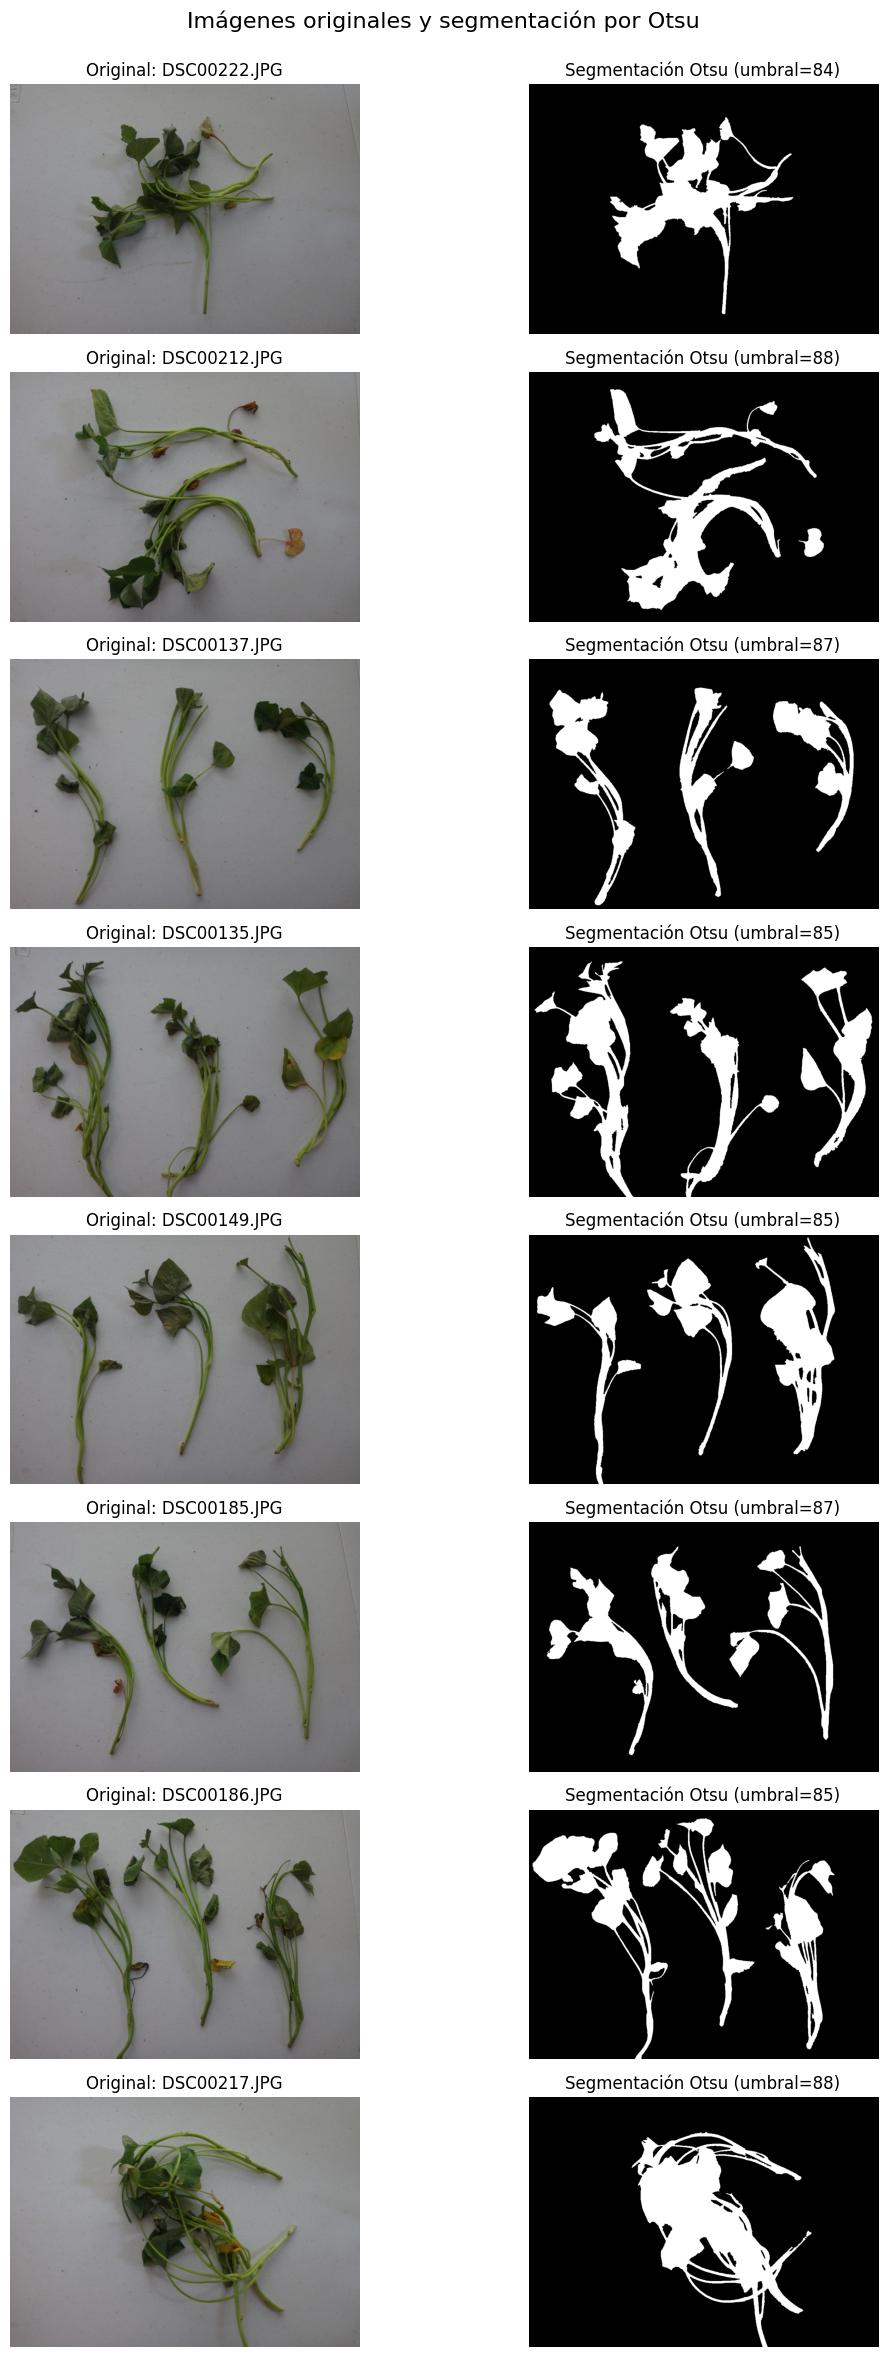

In [14]:
# Seleccionar 8 imágenes aleatorias
muestra = random.sample(archivos, 8)

# Visualizar imágenes originales y máscaras segmentadas
plt.figure(figsize=(12,24))
plt.suptitle('Imágenes originales y segmentación por Otsu', fontsize=16)

for i, archivo in enumerate(muestra):
    # Cargar imagen y recortar
    imagen = imread(ruta + '/' + archivo)
    imagen_recortada = imagen[20:850, 20:1180]

    # Umbralizar canal azul con Otsu
    B = imagen_recortada[:,:,2]
    umbral_otsu = threshold_otsu(B)
    segmentacion_otsu = B < umbral_otsu

    # Postprocesar
    mascara_limpia = postprocesar(segmentacion_otsu)

    # Mostrar imagen original
    plt.subplot(8,2,2*i+1)
    plt.imshow(imagen_recortada)
    plt.title('Original: ' + archivo)
    plt.axis('off')

    # Mostrar máscara segmentada
    plt.subplot(8,2,2*i+2)
    plt.imshow(mascara_limpia, cmap='gray')
    plt.title('Segmentación Otsu (umbral=' + str(umbral_otsu) + ')')
    plt.axis('off')

plt.tight_layout(rect=[0,0,1,0.98])
plt.show()

Segmentación: Machine Learning mediante Gaussian Naive Bayes.

In [15]:
# Leer el archivo de Excel
df = pd.read_excel('/content/drive/MyDrive/Proyecto_Final/Entrenamiento Bayes/datos_RGB_Bayes_500_.xlsx')

print(df.info())

# Separar características (X) y etiquetas (y)
X = df[['R', 'G', 'B']]
y = df['Clase']

# Consultar los tipos de datos
print("Tipo de dato de cada columna:")
print(df.dtypes)
print(df['Clase'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   R       500 non-null    int64 
 1   G       500 non-null    int64 
 2   B       500 non-null    int64 
 3   Clase   500 non-null    object
dtypes: int64(3), object(1)
memory usage: 15.8+ KB
None
Tipo de dato de cada columna:
R         int64
G         int64
B         int64
Clase    object
dtype: object
Clase
Fondo     250
Planta    250
Name: count, dtype: int64


In [16]:
le = LabelEncoder()
y_codificado = le.fit_transform(y)

print(y_codificado)
print(le.classes_)

print('0 = Fondo')
print('1 = Planta')
print('Total de datos:', len(y_codificado))

# Etiqueta numérica de la clase Planta (evita asumir el orden)
etiqueta_planta = int(le.transform(['Planta'])[0])

[0 0 1 1 0 0 0 1 1 1 0 1 1 1 0 1 0 0 1 1 0 0 0 0 1 0 1 0 1 1 1 0 1 0 0 1 0
 1 0 0 0 0 0 1 0 0 0 0 0 1 1 1 1 0 0 1 0 0 1 0 0 1 0 0 0 0 0 0 0 1 0 0 1 1
 1 0 0 0 0 1 0 1 1 0 1 1 0 0 0 0 0 0 0 1 0 1 1 1 1 1 1 0 0 1 0 1 0 1 1 1 0
 0 0 0 0 1 0 1 1 0 0 1 1 0 1 0 0 0 1 1 0 1 0 1 0 0 0 0 0 1 1 1 1 0 1 0 1 1
 1 1 1 1 0 1 0 0 1 1 1 0 1 0 0 0 0 0 1 1 0 0 1 1 0 1 1 1 1 1 1 1 0 0 0 1 0
 0 1 1 1 0 1 1 0 0 1 0 1 0 1 0 0 0 0 1 1 0 1 1 1 0 1 1 0 1 1 1 1 1 1 1 1 1
 0 1 0 1 0 0 0 0 0 1 0 0 0 1 1 0 0 1 1 1 1 1 0 0 1 0 0 0 0 0 1 1 0 0 0 0 0
 1 0 0 1 0 1 1 0 1 1 0 0 1 0 1 0 1 1 0 1 1 1 1 0 1 1 1 1 0 0 1 1 0 0 1 0 0
 0 1 0 0 1 1 1 0 0 1 0 1 0 1 1 0 0 1 1 0 1 1 1 1 1 1 0 1 1 0 0 0 1 1 1 0 0
 0 0 1 1 1 0 1 0 1 0 1 1 0 1 1 0 1 0 1 1 1 0 0 0 1 1 1 1 1 1 1 0 0 1 0 1 1
 1 1 0 0 0 1 0 1 0 0 1 1 1 0 0 1 0 1 1 0 0 0 0 0 0 0 1 1 0 0 1 1 0 1 0 1 1
 1 0 0 0 1 1 1 0 1 0 0 0 1 1 0 0 1 1 0 0 1 0 1 1 1 1 0 0 1 0 0 1 1 1 0 1 0
 1 0 0 0 1 1 0 1 0 1 0 1 0 0 1 0 1 0 0 1 0 1 1 0 1 1 1 1 0 0 1 0 0 0 0 0 0
 0 1 0 0 1 1 0 1 1 0 0 1 

In [17]:
# Split estratificado (mantiene la proporción de clases)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_codificado, test_size=0.2, random_state=42, stratify=y_codificado)

for item in [X_train, X_test, y_train, y_test]:
    print(item.shape)

(400, 3)
(100, 3)
(400,)
(100,)


In [18]:
modelo = GaussianNB()
modelo.fit(X_train, y_train)
print("modelo ha sido entrenado exitosamente")

modelo ha sido entrenado exitosamente


In [19]:
from sklearn.metrics import precision_score

prediccion = modelo.predict(X_test)
print(prediccion)
print(prediccion.ndim)
print("accuracy =", modelo.score(X_test, y_test))

# Precisión para Fondo (0) y Planta (1)
precision = precision_score(y_test, prediccion, average=None)

tabla = pd.DataFrame({
    'Clase': le.classes_,
    'Precision': precision
})
print(tabla.round(3))

[1 1 0 1 0 1 1 1 1 0 0 0 1 1 1 0 1 1 1 0 1 1 1 0 0 0 1 0 0 0 1 1 0 1 0 0 0
 0 0 1 1 0 0 1 0 0 1 0 1 0 0 0 0 1 1 0 0 0 1 0 1 0 1 0 1 0 1 1 0 1 1 0 0 1
 0 1 1 1 1 1 1 1 0 0 0 1 1 0 0 1 0 1 0 0 1 1 0 0 0 0]
1
accuracy = 0.89
    Clase  Precision
0   Fondo      0.882
1  Planta      0.898


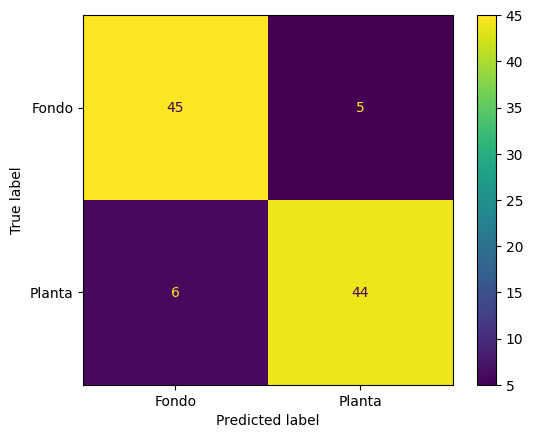

In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

matriz = confusion_matrix(y_test, prediccion)
disp = ConfusionMatrixDisplay(confusion_matrix=matriz, display_labels=le.classes_)
disp.plot()
plt.show()

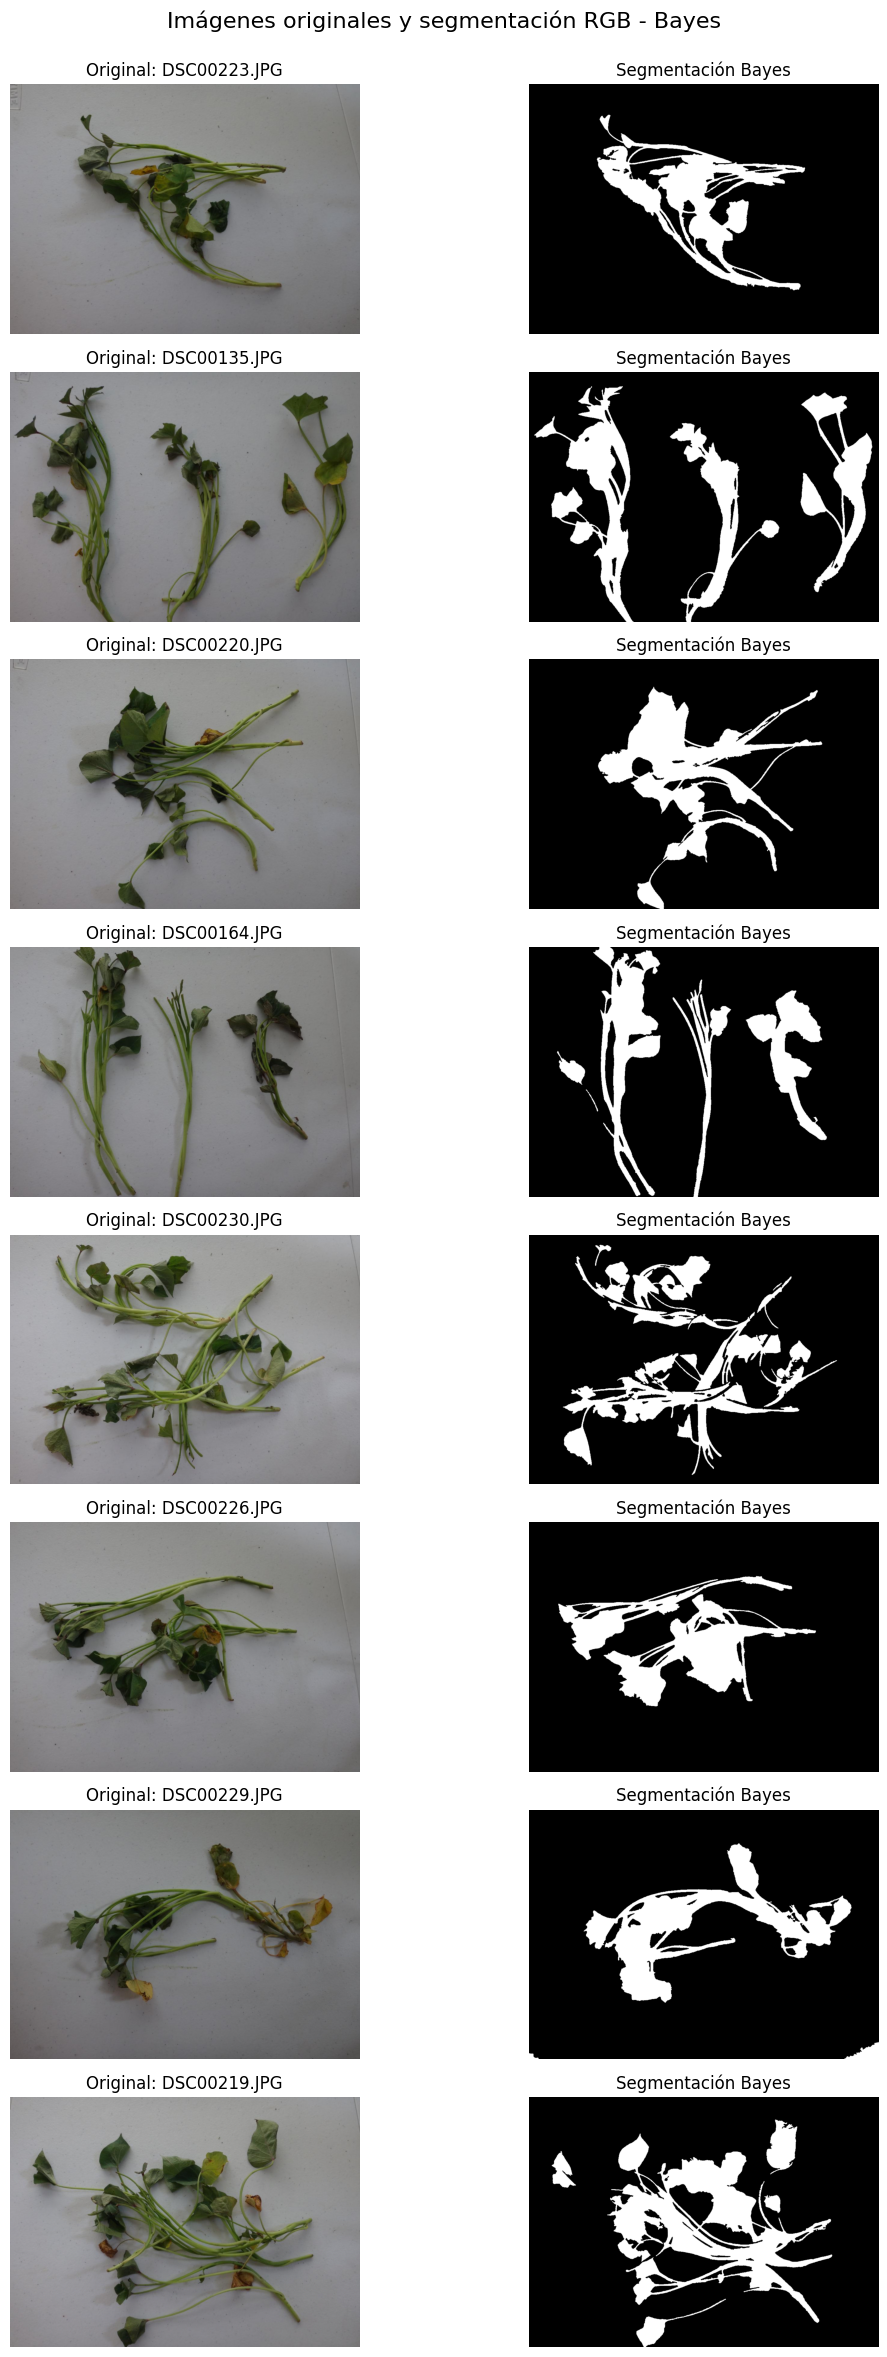

In [21]:
# Seleccionar 8 imágenes aleatorias
muestra = random.sample(archivos, 8)

# Visualizar imágenes originales y máscaras segmentadas
plt.figure(figsize=(12,24))
plt.suptitle('Imágenes originales y segmentación RGB - Bayes', fontsize=16)

for i, archivo in enumerate(muestra):
    # Cargar imagen y recortar primero
    imagen = imread(ruta + '/' + archivo)
    imagenrgb = imagen[20:850, 20:1180, :3]

    # Preparar los píxeles
    pixels = imagenrgb.reshape(-1,3)
    pixels = pd.DataFrame(pixels, columns=['R', 'G', 'B'])

    # Clasificar los píxeles
    pixels_pred = modelo.predict(pixels)

    filas_img = imagenrgb.shape[0]
    columnas_img = imagenrgb.shape[1]
    segmentacion = (pixels_pred == etiqueta_planta).reshape(filas_img,columnas_img)

    # Postprocesar
    mascara_limpia = postprocesar(segmentacion)

    # Mostrar imagen original
    plt.subplot(8,2,2*i+1)
    plt.imshow(imagenrgb)
    plt.title('Original: ' + archivo)
    plt.axis('off')

    # Mostrar máscara segmentada
    plt.subplot(8,2,2*i+2)
    plt.imshow(mascara_limpia, cmap='gray')
    plt.title('Segmentación Bayes')
    plt.axis('off')

plt.tight_layout(rect=[0,0,1,0.98])
plt.show()

Área y Perímetro: Umbralización RGB.

In [22]:
from google.colab import files
pcv.outputs.clear()
verif = []

for archivo in archivos[:60]:
    imagen = imread(ruta + '/' + archivo)
    imagen_recortada = np.ascontiguousarray(imagen[20:850, 20:1180, :3])

    B = imagen_recortada[:,:,2]
    segmentacion = B < 85

    mascara_limpia = postprocesar(segmentacion)

    pcv.analyze.size(
        img=imagen_recortada,
        labeled_mask=mascara_limpia.astype(np.uint8),
        label=archivo
    )

    props = regionprops(label(mascara_limpia))
    verif.append([archivo, len(props), sum(p.area for p in props), sum(p.perimeter for p in props)])

    print('Imagen analizada:', archivo)

pcv.outputs.save_results(
    filename='resultados_RGB.csv',
    outformat="csv"
)

df = pd.read_csv('resultados_RGB.csv')

df = df[df['trait'].isin(['area', 'perimeter'])]

df_resultados = df.pivot_table(
    index='sample',
    columns='trait',
    values='value',
    aggfunc='first'
).reset_index()

df_resultados.columns.name = None
df_resultados = df_resultados.rename(columns={    'sample': 'Imagen',
    'area': 'Area',
    'perimeter': 'Perimetro'
})

# Quitar el sufijo "_1" que agrega PlantCV al nombre de la imagen
df_resultados['Imagen'] = df_resultados['Imagen'].str.replace(r'_\d+$', '', regex=True)

# Verificación independiente con scikit-image
df_verif = pd.DataFrame(verif, columns=['Imagen', 'N_objetos', 'Area_skimage', 'Perimetro_skimage'])
df_resultados = df_resultados.merge(df_verif, on='Imagen')

# Conversión a unidades reales (si se definió la escala)
if escala:
    for c in ['Area', 'Area_skimage']:
        df_resultados[c] = df_resultados[c] * escala**2
    for c in ['Perimetro', 'Perimetro_skimage']:
        df_resultados[c] = df_resultados[c] * escala

df_resultados.to_excel('Area_y_Perimetro.xlsx', index=False)

files.download('Area_y_Perimetro.xlsx')

Imagen analizada: DSC00134.JPG
Imagen analizada: DSC00135.JPG
Imagen analizada: DSC00137.JPG
Imagen analizada: DSC00139.JPG
Imagen analizada: DSC00144.JPG
Imagen analizada: DSC00149.JPG
Imagen analizada: DSC00152.JPG
Imagen analizada: DSC00155.JPG
Imagen analizada: DSC00158.JPG
Imagen analizada: DSC00159.JPG
Imagen analizada: DSC00161.JPG
Imagen analizada: DSC00163.JPG
Imagen analizada: DSC00164.JPG
Imagen analizada: DSC00185.JPG
Imagen analizada: DSC00186.JPG
Imagen analizada: DSC00187.JPG
Imagen analizada: DSC00188.JPG
Imagen analizada: DSC00199.JPG
Imagen analizada: DSC00200.JPG
Imagen analizada: DSC00202.JPG
Imagen analizada: DSC00203.JPG
Imagen analizada: DSC00205.JPG
Imagen analizada: DSC00206.JPG
Imagen analizada: DSC00208.JPG
Imagen analizada: DSC00209.JPG
Imagen analizada: DSC00210.JPG
Imagen analizada: DSC00211.JPG
Imagen analizada: DSC00212.JPG
Imagen analizada: DSC00213.JPG
Imagen analizada: DSC00214.JPG
Imagen analizada: DSC00215.JPG
Imagen analizada: DSC00216.JPG
Imagen a

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Área y Perímetro: Método de Otsu.

In [23]:
pcv.outputs.clear()
verif = []

for archivo in archivos[:60]:
    imagen = imread(ruta + '/' + archivo)
    imagen_recortada = np.ascontiguousarray(imagen[20:850, 20:1180, :3])

    B = imagen_recortada[:,:,2]
    umbral = threshold_otsu(B)
    segmentacion = B < umbral

    mascara_limpia = postprocesar(segmentacion)

    pcv.analyze.size(
        img=imagen_recortada,
        labeled_mask=mascara_limpia.astype(np.uint8),
        label=archivo
    )

    props = regionprops(label(mascara_limpia))
    verif.append([archivo, len(props), sum(p.area for p in props), sum(p.perimeter for p in props)])

    print('Imagen analizada:', archivo)

pcv.outputs.save_results(
    filename='resultados_Otsu.csv',
    outformat="csv"
)

df = pd.read_csv('resultados_Otsu.csv')

df = df[df['trait'].isin(['area', 'perimeter'])]

df_resultados = df.pivot_table(
    index='sample',
    columns='trait',
    values='value',
    aggfunc='first'
).reset_index()

df_resultados.columns.name = None
df_resultados = df_resultados.rename(columns={
    'sample': 'Imagen',
    'area': 'Area',
    'perimeter': 'Perimetro'
})

# Quitar el sufijo "_1" que agrega PlantCV al nombre de la imagen
df_resultados['Imagen'] = df_resultados['Imagen'].str.replace(r'_\d+$', '', regex=True)

# Verificación independiente con scikit-image
df_verif = pd.DataFrame(verif, columns=['Imagen', 'N_objetos', 'Area_skimage', 'Perimetro_skimage'])
df_resultados = df_resultados.merge(df_verif, on='Imagen')

# Conversión a unidades reales (si se definió la escala)
if escala:
    for c in ['Area', 'Area_skimage']:
        df_resultados[c] = df_resultados[c] * escala**2
    for c in ['Perimetro', 'Perimetro_skimage']:
        df_resultados[c] = df_resultados[c] * escala

df_resultados.to_excel('Area_y_Perimetro_Otsu.xlsx', index=False)

files.download('Area_y_Perimetro_Otsu.xlsx')

Imagen analizada: DSC00134.JPG
Imagen analizada: DSC00135.JPG
Imagen analizada: DSC00137.JPG
Imagen analizada: DSC00139.JPG
Imagen analizada: DSC00144.JPG
Imagen analizada: DSC00149.JPG
Imagen analizada: DSC00152.JPG
Imagen analizada: DSC00155.JPG
Imagen analizada: DSC00158.JPG
Imagen analizada: DSC00159.JPG
Imagen analizada: DSC00161.JPG
Imagen analizada: DSC00163.JPG
Imagen analizada: DSC00164.JPG
Imagen analizada: DSC00185.JPG
Imagen analizada: DSC00186.JPG
Imagen analizada: DSC00187.JPG
Imagen analizada: DSC00188.JPG
Imagen analizada: DSC00199.JPG
Imagen analizada: DSC00200.JPG
Imagen analizada: DSC00202.JPG
Imagen analizada: DSC00203.JPG
Imagen analizada: DSC00205.JPG
Imagen analizada: DSC00206.JPG
Imagen analizada: DSC00208.JPG
Imagen analizada: DSC00209.JPG
Imagen analizada: DSC00210.JPG
Imagen analizada: DSC00211.JPG
Imagen analizada: DSC00212.JPG
Imagen analizada: DSC00213.JPG
Imagen analizada: DSC00214.JPG
Imagen analizada: DSC00215.JPG
Imagen analizada: DSC00216.JPG
Imagen a

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Área y Perímetro: Machine Learning mediante Gaussian Naive Bayes.

In [24]:
pcv.outputs.clear()
verif = []

for archivo in archivos[:60]:
    imagen = imread(ruta + '/' + archivo)
    imagen_recortada = np.ascontiguousarray(imagen[20:850, 20:1180, :3])

    pixels = imagen_recortada.reshape(-1,3)
    pixels = pd.DataFrame(pixels, columns=['R', 'G', 'B'])

    pixels_pred = modelo.predict(pixels)

    filas_img = imagen_recortada.shape[0]
    columnas_img = imagen_recortada.shape[1]
    segmentacion = (pixels_pred == etiqueta_planta).reshape(filas_img, columnas_img)

    mascara_limpia = postprocesar(segmentacion)

    pcv.analyze.size(
        img=imagen_recortada,
        labeled_mask=mascara_limpia.astype(np.uint8),
        label=archivo
    )

    props = regionprops(label(mascara_limpia))
    verif.append([archivo, len(props), sum(p.area for p in props), sum(p.perimeter for p in props)])

    print('Imagen analizada:', archivo)

pcv.outputs.save_results(
    filename='resultados_Bayes.csv',
    outformat="csv"
)

df = pd.read_csv('resultados_Bayes.csv')

df = df[df['trait'].isin(['area', 'perimeter'])]

df_resultados = df.pivot_table(
    index='sample',
    columns='trait',
    values='value',
    aggfunc='first'
).reset_index()

df_resultados.columns.name = None
df_resultados = df_resultados.rename(columns={
    'sample': 'Imagen',
    'area': 'Area',
    'perimeter': 'Perimetro'
})

# Quitar el sufijo "_1" que agrega PlantCV al nombre de la imagen
df_resultados['Imagen'] = df_resultados['Imagen'].str.replace(r'_\d+$', '', regex=True)

# Verificación independiente con scikit-image
df_verif = pd.DataFrame(verif, columns=['Imagen', 'N_objetos', 'Area_skimage', 'Perimetro_skimage'])
df_resultados = df_resultados.merge(df_verif, on='Imagen')

# Conversión a unidades reales (si se definió la escala)
if escala:
    for c in ['Area', 'Area_skimage']:
        df_resultados[c] = df_resultados[c] * escala**2
    for c in ['Perimetro', 'Perimetro_skimage']:
        df_resultados[c] = df_resultados[c] * escala

df_resultados.to_excel('Area_y_Perimetro_Bayes.xlsx', index=False)

files.download('Area_y_Perimetro_Bayes.xlsx')

Imagen analizada: DSC00134.JPG
Imagen analizada: DSC00135.JPG
Imagen analizada: DSC00137.JPG
Imagen analizada: DSC00139.JPG
Imagen analizada: DSC00144.JPG
Imagen analizada: DSC00149.JPG
Imagen analizada: DSC00152.JPG
Imagen analizada: DSC00155.JPG
Imagen analizada: DSC00158.JPG
Imagen analizada: DSC00159.JPG
Imagen analizada: DSC00161.JPG
Imagen analizada: DSC00163.JPG
Imagen analizada: DSC00164.JPG
Imagen analizada: DSC00185.JPG
Imagen analizada: DSC00186.JPG
Imagen analizada: DSC00187.JPG
Imagen analizada: DSC00188.JPG
Imagen analizada: DSC00199.JPG
Imagen analizada: DSC00200.JPG
Imagen analizada: DSC00202.JPG
Imagen analizada: DSC00203.JPG
Imagen analizada: DSC00205.JPG
Imagen analizada: DSC00206.JPG
Imagen analizada: DSC00208.JPG
Imagen analizada: DSC00209.JPG
Imagen analizada: DSC00210.JPG
Imagen analizada: DSC00211.JPG
Imagen analizada: DSC00212.JPG
Imagen analizada: DSC00213.JPG
Imagen analizada: DSC00214.JPG
Imagen analizada: DSC00215.JPG
Imagen analizada: DSC00216.JPG
Imagen a

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Estadísticos base y pruebas estadísticas


In [25]:
from scipy import stats
from matplotlib.ticker import MaxNLocator, FuncFormatter

# Parte A: Estadísticos base de los datos

## Base 1: Tabla de estadísticos descriptivos
*¿Cuál es el valor típico, qué tanto varía y cuáles son los extremos?* La variación (%) es la desviación estándar sobre la media, y permite comparar el área con el perímetro.

In [27]:
import pandas as pd

# Definir los métodos
metodos = ['RGB', 'Otsu', 'Bayes']

# Cargar y unificar los tres conjuntos de resultados
df_rgb = pd.read_excel('Area_y_Perimetro.xlsx')[['Imagen', 'Area', 'Perimetro']].rename(columns={'Area': 'Area_RGB', 'Perimetro': 'Perimetro_RGB'})
df_otsu = pd.read_excel('Area_y_Perimetro_Otsu.xlsx')[['Imagen', 'Area', 'Perimetro']].rename(columns={'Area': 'Area_Otsu', 'Perimetro': 'Perimetro_Otsu'})
df_bayes = pd.read_excel('Area_y_Perimetro_Bayes.xlsx')[['Imagen', 'Area', 'Perimetro']].rename(columns={'Area': 'Area_Bayes', 'Perimetro': 'Perimetro_Bayes'})

# Unir todos en un único DataFrame df
df = df_rgb.merge(df_otsu, on='Imagen').merge(df_bayes, on='Imagen')

# También definimos los pares para las celdas posteriores que los usan
pares = [('RGB', 'Otsu'), ('RGB', 'Bayes'), ('Otsu', 'Bayes')]

resumen = []
for variable in ['Area', 'Perimetro']:
    for m in metodos:
        x = df[variable + '_' + m]
        resumen.append([variable, m, len(x), x.mean(), x.median(), x.std(), x.min(), x.quantile(0.25), x.quantile(0.75), x.max(), x.std() / x.mean() * 100])

tabla_base = pd.DataFrame(resumen, columns=['Variable', 'Método', 'n', 'Media', 'Mediana', 'Desv. estándar', 'Mínimo', 'Q1', 'Q3', 'Máximo', 'Variación (%)'])
print(tabla_base.round(1).to_string(index=False))

 Variable Método  n    Media  Mediana  Desv. estándar  Mínimo       Q1       Q3   Máximo  Variación (%)
     Area    RGB 60 127523.8 122704.0         33783.8 57992.0 109080.0 139982.0 256924.0           26.5
     Area   Otsu 60 130613.8 125185.5         37262.3 57353.0 108058.8 143847.8 281546.0           28.5
     Area  Bayes 60 126653.5 122855.5         33246.3 56832.0 108202.8 138399.5 253763.0           26.2
Perimetro    RGB 60   7710.8   7906.9          2373.0  3104.0   5689.9   9648.1  12139.0           30.8
Perimetro   Otsu 60   7538.8   7644.3          2321.2  3109.4   5226.6   9233.6  12878.0           30.8
Perimetro  Bayes 60   8298.4   8460.5          2502.7  3260.4   6092.0  10064.8  16610.0           30.2


## Base 2: Distribución de los datos (histogramas)
*¿Cómo se reparten los valores?* Si la media (roja) se aleja de la mediana (verde), la distribución es asimétrica o tiene valores extremos.

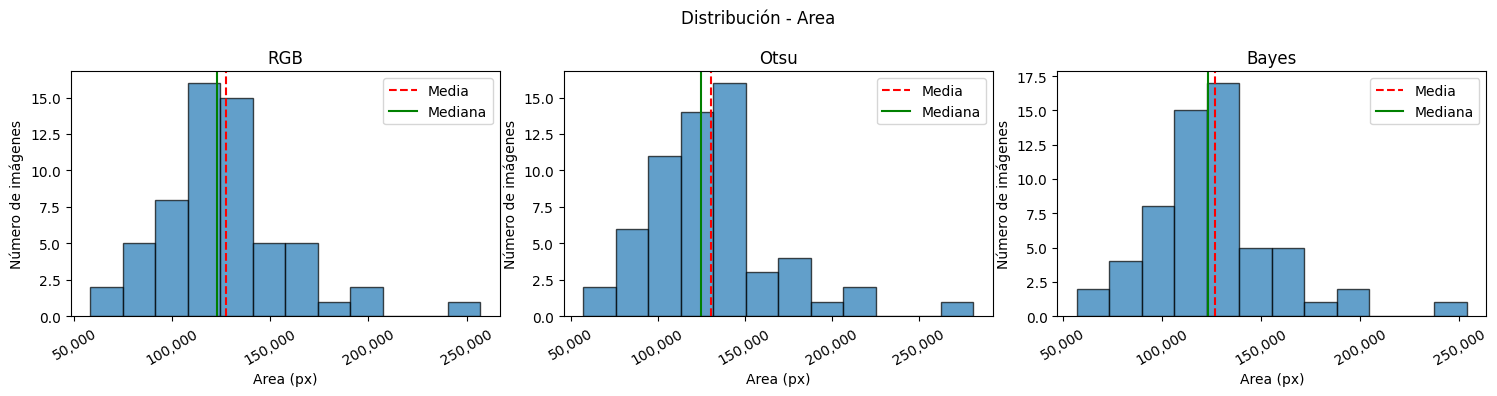

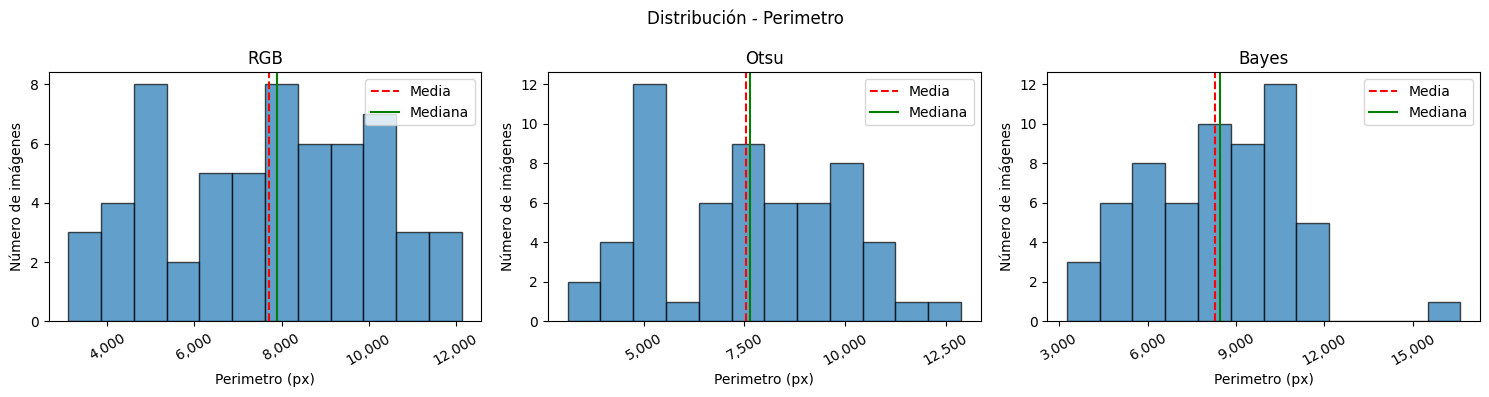

In [28]:
for variable in ['Area', 'Perimetro']:
    plt.figure(figsize=(15,4))
    for i, m in enumerate(metodos):
        x = df[variable + '_' + m]
        plt.subplot(1,3,i+1)
        plt.hist(x, bins=12, edgecolor='black', alpha=0.7)
        plt.axvline(x.mean(), color='r', linestyle='--', label='Media')
        plt.axvline(x.median(), color='g', linestyle='-', label='Mediana')
        plt.gca().xaxis.set_major_locator(MaxNLocator(nbins=5))
        plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda v, pos: '{:,.0f}'.format(v)))
        plt.xticks(rotation=30)
        plt.xlabel(variable + ' (px)')
        plt.ylabel('Número de imágenes')
        plt.title(m)
        plt.legend()
    plt.suptitle('Distribución - ' + variable)
    plt.tight_layout()
    plt.show()

## Base 3: Boxplot y valores atípicos
*¿Hay valores extremos?* El triángulo es la media, la línea del centro es la mediana y los puntos fuera de los bigotes son valores atípicos.

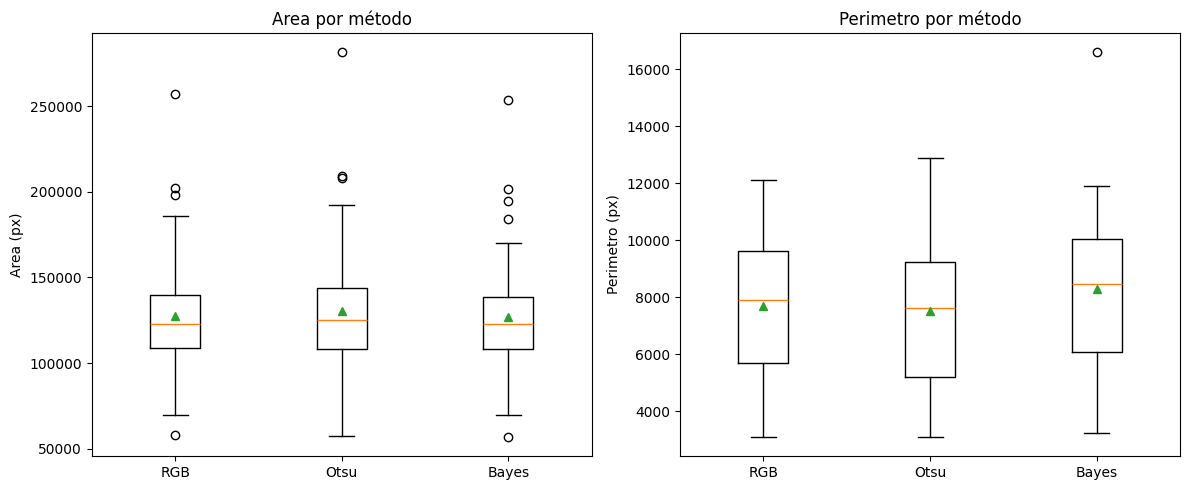

 Variable Método  Valores atípicos
     Area    RGB                 4
     Area   Otsu                 3
     Area  Bayes                 5
Perimetro    RGB                 0
Perimetro   Otsu                 0
Perimetro  Bayes                 1


In [29]:
plt.figure(figsize=(12,5))
for i, variable in enumerate(['Area', 'Perimetro']):
    plt.subplot(1,2,i+1)
    plt.boxplot([df[variable + '_' + m] for m in metodos], showmeans=True)
    plt.xticks(range(1, len(metodos) + 1), metodos)
    plt.title(variable + ' por método')
    plt.ylabel(variable + ' (px)')
plt.tight_layout()
plt.show()

filas = []
for variable in ['Area', 'Perimetro']:
    for m in metodos:
        x = df[variable + '_' + m]
        q1, q3 = x.quantile(0.25), x.quantile(0.75)
        atipicos = ((x < q1 - 1.5 * (q3 - q1)) | (x > q3 + 1.5 * (q3 - q1))).sum()
        filas.append([variable, m, atipicos])

tabla_atipicos = pd.DataFrame(filas, columns=['Variable', 'Método', 'Valores atípicos'])
print(tabla_atipicos.to_string(index=False))

## Base 4: Prueba de normalidad (Shapiro-Wilk)
*¿Los datos siguen una distribución normal?* Si p < 0.05 no son normales, y por eso se usan pruebas no paramétricas.

In [30]:
filas = []
for variable in ['Area', 'Perimetro']:
    for m in metodos:
        x = df[variable + '_' + m]
        estadistico, p = stats.shapiro(x)
        filas.append([variable, m, x.skew(), '%.3f' % p, 'Sí' if p > 0.05 else 'No'])

tabla_normal = pd.DataFrame(filas, columns=['Variable', 'Método', 'Asimetría', 'Valor p (Shapiro)', '¿Distribución normal?'])
print(tabla_normal.round(2).to_string(index=False))

 Variable Método  Asimetría Valor p (Shapiro) ¿Distribución normal?
     Area    RGB       1.08             0.006                    No
     Area   Otsu       1.28             0.001                    No
     Area  Bayes       1.08             0.005                    No
Perimetro    RGB      -0.14             0.122                    Sí
Perimetro   Otsu       0.06             0.205                    Sí
Perimetro  Bayes       0.28             0.111                    Sí


# Parte B: Pruebas estadísticas

Se usan las mismas pruebas no paramétricas para área y perímetro: el área no es normal y tiene atípicos, y el perímetro tiene un atípico extremo en Bayes. Además, al usar las mismas pruebas, ambas variables son comparables.

## Prueba 1: Friedman
*¿Los tres métodos difieren?* Compara los 3 métodos medidos sobre las mismas 60 imágenes. Si p < 0.05, al menos un método es distinto.

In [31]:
filas = []
friedman_p = {}
for variable in ['Area', 'Perimetro']:
    est, p = stats.friedmanchisquare(*[df[variable + '_' + m] for m in metodos])
    friedman_p[variable] = p
    filas.append([variable, est, '%.4f' % p, 'Sí' if p < 0.05 else 'No'])

tabla_friedman = pd.DataFrame(filas, columns=['Variable', 'Estadístico', 'Valor p', '¿Difieren los métodos?'])
print(tabla_friedman.round(2).to_string(index=False))

 Variable  Estadístico Valor p ¿Difieren los métodos?
     Area        32.69  0.0000                     Sí
Perimetro        54.86  0.0000                     Sí


## Prueba 2: Wilcoxon por pares (corrección de Bonferroni)
*¿Cuáles métodos difieren?* Compara cada par de métodos imagen por imagen. Con 3 pares, el nivel de significancia baja de 0.05 a 0.05 / 3.

In [32]:
alfa = 0.05 / len(pares)
filas = []
wilcoxon_sig = {'Area': [], 'Perimetro': []}
for variable in ['Area', 'Perimetro']:
    for a, b in pares:
        x = df[variable + '_' + a]
        y = df[variable + '_' + b]
        est, p = stats.wilcoxon(x, y)
        dif = abs(x.mean() - y.mean()) / ((x.mean() + y.mean()) / 2) * 100
        if p < alfa:
            wilcoxon_sig[variable].append(a + ' vs ' + b)
        filas.append([variable, a + ' vs ' + b, dif, '%.4f' % p, 'Sí' if p < alfa else 'No'])

tabla_wilcoxon = pd.DataFrame(filas, columns=['Variable', 'Par de métodos', 'Diferencia de medias (%)', 'Valor p', '¿Difieren? (p < %.4f)' % alfa])
print(tabla_wilcoxon.round(2).to_string(index=False))

 Variable Par de métodos  Diferencia de medias (%) Valor p ¿Difieren? (p < 0.0167)
     Area    RGB vs Otsu                      2.39  0.0000                      Sí
     Area   RGB vs Bayes                      0.68  0.0008                      Sí
     Area  Otsu vs Bayes                      3.08  0.0000                      Sí
Perimetro    RGB vs Otsu                      2.26  0.0116                      Sí
Perimetro   RGB vs Bayes                      7.34  0.0000                      Sí
Perimetro  Otsu vs Bayes                      9.59  0.0000                      Sí


## Prueba 3: Wilcoxon de sensibilidad (perímetro vs área)
*¿El perímetro es más sensible que el área?* Para cada imagen se calcula la diferencia relativa (%) entre dos métodos, en el área y en el perímetro, y se comparan ambas con Wilcoxon pareado.

In [33]:
filas = []
sensibilidad = []
for a, b in pares:
    dif = {}
    for variable in ['Area', 'Perimetro']:
        x = df[variable + '_' + a]
        y = df[variable + '_' + b]
        dif[variable] = abs(x - y) / ((x + y) / 2) * 100
    est, p = stats.wilcoxon(dif['Perimetro'], dif['Area'])
    mayor = dif['Perimetro'].median() > dif['Area'].median()
    if p < alfa and mayor:
        sensibilidad.append(a + ' vs ' + b)
    filas.append([a + ' vs ' + b, dif['Area'].median(), dif['Perimetro'].median(), '%.4f' % p, 'Sí' if (p < alfa and mayor) else 'No'])

tabla_sensibilidad = pd.DataFrame(filas, columns=['Par de métodos', 'Mediana dif. Área (%)', 'Mediana dif. Perímetro (%)', 'Valor p', '¿Perímetro más sensible?'])
print(tabla_sensibilidad.round(2).to_string(index=False))

Par de métodos  Mediana dif. Área (%)  Mediana dif. Perímetro (%) Valor p ¿Perímetro más sensible?
   RGB vs Otsu                   2.11                        1.19  0.5600                       No
  RGB vs Bayes                   1.02                        6.08  0.0000                       Sí
 Otsu vs Bayes                   2.70                        7.30  0.0000                       Sí


## Resumen automático

In [34]:
for variable in ['Area', 'Perimetro']:
    if friedman_p[variable] < 0.05:
        pares_sig = ', '.join(wilcoxon_sig[variable]) if wilcoxon_sig[variable] else 'ningún par tras Bonferroni'
        print(variable + ': los métodos difieren (Friedman p = %.4f). Pares distintos: %s.' % (friedman_p[variable], pares_sig))
    else:
        print(variable + ': no hay diferencias entre métodos (Friedman p = %.4f).' % friedman_p[variable])

if sensibilidad:
    print('Sensibilidad: el perímetro es más sensible que el área en ' + ', '.join(sensibilidad) + '.')
else:
    print('Sensibilidad: no hay evidencia de que el perímetro sea más sensible que el área.')

Area: los métodos difieren (Friedman p = 0.0000). Pares distintos: RGB vs Otsu, RGB vs Bayes, Otsu vs Bayes.
Perimetro: los métodos difieren (Friedman p = 0.0000). Pares distintos: RGB vs Otsu, RGB vs Bayes, Otsu vs Bayes.
Sensibilidad: el perímetro es más sensible que el área en RGB vs Bayes, Otsu vs Bayes.
